<a href="https://colab.research.google.com/github/contreras-juan/procesamiento_lenguaje_natural/blob/main/Ejercicios/Soluciones/08_Taller_Transformers_Solucion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color: #FECB05; text-align: center;">Taller práctico: atención, Transformers y modelos preentrenados (solución)</h1>

<h2 style="color: #007ACC;">Autores</h2>

- [Juan Felipe Contreras Alcívar](https://www.linkedin.com/in/juanf-contreras/)

---

<h2 style="color: #007ACC;">Instrucciones</h2>

Solución de referencia del taller [`08_Taller_Transformers.ipynb`](../08_Taller_Transformers.ipynb).

Hay muchas soluciones válidas: esta es una de ellas. Compara tus resultados y, sobre todo, tus conclusiones.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [<span style="color: #005C99;">Ejercicio 1. Self-attention desde cero</span>](#ejercicio-1)
- [<span style="color: #005C99;">Ejercicio 2. Bloque Transformer en PyTorch</span>](#ejercicio-2)
- [<span style="color: #005C99;">Ejercicio 3. Fine-tuning de BERT</span>](#ejercicio-3)
- [<span style="color: #005C99;">Ejercicio 4. Sumarización y QA</span>](#ejercicio-4)

---

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib seaborn scikit-learn datasets "transformers>=5" accelerate torch sentencepiece rouge_score

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import transformers
from transformers import AutoTokenizer, pipeline, set_seed
import re
import torch.nn as nn
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
set_seed(SEED)  # fija las semillas de Python, NumPy y PyTorch
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
print(f"transformers {transformers.__version__} | PyTorch {torch.__version__} | dispositivo: {dispositivo}")

transformers 5.20.2 | PyTorch 2.11.0+cu128 | dispositivo: cuda


---

<a id="ejercicio-1"></a>
<h2 style="color: #007ACC;">Ejercicio 1. Self-attention desde cero</h2>

**Objetivo:** implementar la multi-head self-attention con máscaras, verificarla contra `torch.nn.MultiheadAttention` y medir su costo en función de la longitud.

1. Implementa en NumPy `multi_head(X, W_in, b_in, W_out, b_out, h, mascara_causal=False, relleno=None)` que replique a `torch.nn.MultiheadAttention` (con `batch_first=True`) para **una** secuencia `X` de forma `(T, d)`:
   - `W_in` tiene forma `(3d, d)` y contiene, apiladas, las matrices de consultas, claves y valores; cada una se aplica como `X @ W.T + b`.
   - Cada cabeza usa un bloque consecutivo de $d/h$ columnas de $Q$, $K$ y $V$.
   - `relleno` es un vector booleano de longitud $T$ con `True` en las posiciones de **relleno**, a las que nadie debe atender.
   - La función debe devolver la salida `(T, d)` y los pesos de atención `(h, T, T)`.
2. Verifica tu implementación contra `nn.MultiheadAttention(d, h, batch_first=True)` en tres casos: sin máscara, con máscara causal y con relleno en las 2 últimas posiciones. Atención: en PyTorch, `attn_mask` y `key_padding_mask` marcan con `True` las posiciones **prohibidas**, al revés que la máscara de Keras del cuaderno 16. Compara también los pesos (usa `need_weights=True, average_attn_weights=False`).
3. Mide el tiempo de tu función con una sola cabeza, `d = 64`, para $T \in \{256, 512, 1024, 2048, 4096\}$, tomando el mínimo de 3 repeticiones. Para que la medición sea estable, limita NumPy a un solo hilo con `threadpoolctl.threadpool_limits(1)`. Grafica en escala log-log y estima la pendiente con los tres valores más grandes. ¿Es cuadrática? ¿Cuánta memoria ocupa la matriz de pesos con $T = 100\,000$ (en float32)?

In [3]:
def softmax(x):
    e = np.exp(x - x.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def multi_head(X, W_in, b_in, W_out, b_out, h, mascara_causal=False, relleno=None):
    T, d = X.shape
    Q, K, V = np.split(X @ W_in.T + b_in, 3, axis=-1)          # cada una (T, d)
    dk = d // h
    permitido = np.ones((T, T), dtype=bool)
    if mascara_causal:
        permitido &= np.tril(permitido)
    if relleno is not None:
        permitido &= ~relleno[None, :]                         # nadie atiende al relleno
    cabezas, pesos = [], []
    for i in range(h):
        q, k, v = (M[:, i * dk:(i + 1) * dk] for M in (Q, K, V))
        puntajes = np.where(permitido, q @ k.T / np.sqrt(dk), -np.inf)
        p = softmax(puntajes)
        cabezas.append(p @ v)
        pesos.append(p)
    return np.concatenate(cabezas, axis=-1) @ W_out.T + b_out, np.array(pesos)


torch.manual_seed(SEED)
T, d, h = 7, 16, 4
mha = nn.MultiheadAttention(d, h, batch_first=True).eval()
parametros = [p.detach().numpy().astype("float64") for p in
              (mha.in_proj_weight, mha.in_proj_bias, mha.out_proj.weight, mha.out_proj.bias)]
X = torch.randn(1, T, d)
relleno = np.array([False] * (T - 2) + [True] * 2)

casos = {
    "sin máscara": (dict(), dict()),
    "causal": (dict(mascara_causal=True), dict(attn_mask=torch.triu(torch.ones(T, T, dtype=torch.bool), 1))),
    "relleno": (dict(relleno=relleno), dict(key_padding_mask=torch.tensor(relleno)[None])),
}
for nombre, (args_np, args_torch) in casos.items():
    with torch.no_grad():
        salida_t, pesos_t = mha(X, X, X, need_weights=True, average_attn_weights=False, **args_torch)
    salida_np, pesos_np = multi_head(X[0].numpy().astype("float64"), *parametros, h, **args_np)
    print(f"{nombre:<12} salida: {np.allclose(salida_np, salida_t[0].numpy(), atol=1e-5)} | "
          f"pesos: {np.allclose(pesos_np, pesos_t[0].numpy(), atol=1e-5)}")

sin máscara  salida: True | pesos: True
causal       salida: True | pesos: True
relleno      salida: True | pesos: True


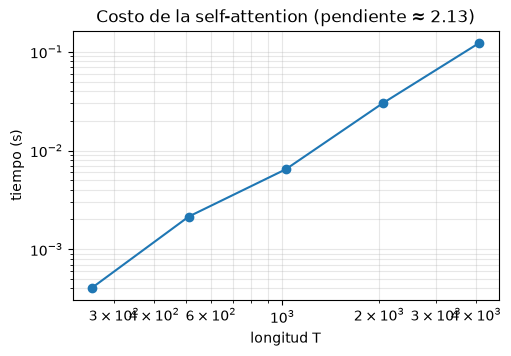

Matriz de pesos con T = 100 000 en float32: 40 GB por cabeza y por capa


In [4]:
from threadpoolctl import threadpool_limits

rng = np.random.default_rng(SEED)
d = 64
W_in, b_in = rng.normal(size=(3 * d, d)) / np.sqrt(d), np.zeros(3 * d)
W_out, b_out = rng.normal(size=(d, d)) / np.sqrt(d), np.zeros(d)
Ts, tiempos = [256, 512, 1024, 2048, 4096], []
with threadpool_limits(1):  # un solo hilo: con varios, el reparto del trabajo distorsiona los tiempos
    for T in Ts:
        X = rng.normal(size=(T, d))
        mejores = []
        for _ in range(3):
            inicio = time.perf_counter()
            multi_head(X, W_in, b_in, W_out, b_out, h=1)
            mejores.append(time.perf_counter() - inicio)
        tiempos.append(min(mejores))

pendiente = np.polyfit(np.log(Ts[2:]), np.log(tiempos[2:]), 1)[0]
plt.figure(figsize=(5.5, 3.5))
plt.loglog(Ts, tiempos, "o-")
plt.xlabel("longitud T")
plt.ylabel("tiempo (s)")
plt.title(f"Costo de la self-attention (pendiente ≈ {pendiente:.2f})")
plt.grid(alpha=0.3, which="both")
plt.show()
print(f"Matriz de pesos con T = 100 000 en float32: {100_000 ** 2 * 4 / 1e9:.0f} GB por cabeza y por capa")

**Interpretación:**

- La implementación coincide con PyTorch, en la salida y en los pesos, en los tres casos. La diferencia de convenciones es una fuente frecuente de errores **silenciosos**: en PyTorch, `True` en la máscara significa *prohibido*; en Keras, *permitido*. Una máscara invertida no produce ningún error, solo un modelo que atiende al relleno o que ve el futuro.
- Al duplicar la longitud, el tiempo se multiplica aproximadamente por 4: la pendiente en escala log-log es 2,13, es decir, un costo **cuadrático**. Con secuencias cortas pesan más las proyecciones lineales, cuyo costo es $O(T d^2)$, y la curva es menos empinada.
- La memoria es un problema aún más serio: con 100 000 tokens, la matriz de pesos ocupa 40 GB por cabeza y por capa. Por eso los modelos de contexto largo usan implementaciones que nunca materializan la matriz completa (FlashAttention; Dao et al., 2022) o restringen la atención a ventanas locales.

---

<a id="ejercicio-2"></a>
<h2 style="color: #007ACC;">Ejercicio 2. Bloque Transformer en PyTorch</h2>

**Objetivo:** implementar un bloque codificador del Transformer en PyTorch y demostrar experimentalmente que, sin codificación posicional, no puede resolver una tarea que depende del orden.

Usaremos una tarea sintética diseñada para que **solo el orden** importe. Cada secuencia tiene 24 tokens: un token `A`, un token `B` y 22 tokens de relleno al azar. La etiqueta es 1 si `A` aparece **antes** que `B`. La celda de código incluye la función que genera los datos (20 000 secuencias de entrenamiento y 4 000 de validación).

1. Implementa `BloqueCodificador(nn.Module)` con `nn.MultiheadAttention` (con `batch_first=True`), conexiones residuales, `LayerNorm` y una red *feed-forward* de dos capas, como en el diagrama del cuaderno 16.
2. Implementa un clasificador `Clasificador(nn.Module)` con: embedding de tokens (dimensión 64), **opcionalmente** un embedding de posiciones aprendido, 0 o más bloques codificadores, promedio sobre la secuencia y una capa lineal de salida a 2 clases.
3. Entrena tres modelos con Adam (tasa $10^{-3}$, lotes de 128, 10 épocas) y reporta la exactitud en validación:
   - (a) **Promedio de embeddings** (sin bloques ni posiciones),
   - (b) **Transformer sin posiciones** (2 bloques, 4 cabezas),
   - (c) **Transformer con posiciones** (2 bloques, 4 cabezas).
4. Explica los resultados a partir de la propiedad de **equivarianza a permutaciones** del cuaderno 16. Para el modelo (c), muestra el mapa de atención del último bloque en un ejemplo: ¿a qué tokens atiende la mayoría de las posiciones?

In [5]:
# Tarea sintética: secuencias de 24 tokens con un "A" (id 0) y un "B" (id 1) en posiciones al azar;
# el resto son tokens de relleno al azar (ids 2 a 21). Etiqueta: 1 si A aparece antes que B.
def generar(n, T=24, V=22, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.integers(2, V, size=(n, T))
    y = np.zeros(n, dtype=np.int64)
    for i in range(n):
        pa, pb = rng.choice(T, size=2, replace=False)
        X[i, pa], X[i, pb] = 0, 1
        y[i] = int(pa < pb)
    return torch.tensor(X), torch.tensor(y)


X_sint_train, y_sint_train = generar(20_000, seed=1)
X_sint_val, y_sint_val = generar(4_000, seed=2)
print(X_sint_train[:2], y_sint_train[:2])

tensor([[11, 12, 17, 21,  2,  4, 18, 20,  6,  8, 19, 10,  7, 18,  7,  1, 14, 12,
          3,  2,  0, 17, 18, 12],
        [18,  8,  1, 17,  4,  8,  4, 11, 21,  0,  9, 10, 20,  6, 12,  7,  2, 17,
          3,  7, 11, 11,  4, 21]]) tensor([0, 0])


(a) promedio de embeddings         exactitud final en validación: 0.487


(b) Transformer sin posiciones     exactitud final en validación: 0.495


(c) Transformer con posiciones     exactitud final en validación: 1.000


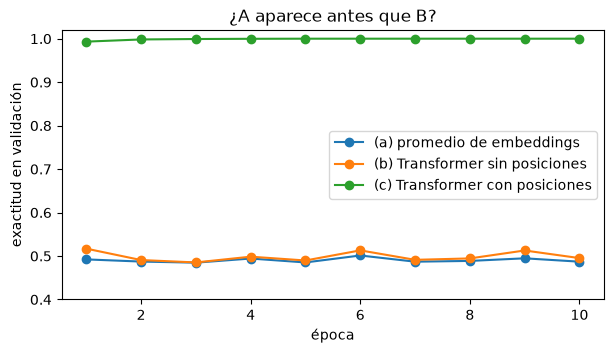

In [6]:
class BloqueCodificador(nn.Module):
    def __init__(self, d, cabezas, d_ff, dropout=0.1):
        super().__init__()
        self.atencion = nn.MultiheadAttention(d, cabezas, dropout=dropout, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, d_ff), nn.ReLU(), nn.Linear(d_ff, d))
        self.norma1, self.norma2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, devolver_pesos=False):
        a, pesos = self.atencion(x, x, x, need_weights=devolver_pesos, average_attn_weights=False)
        x = self.norma1(x + self.drop(a))
        x = self.norma2(x + self.drop(self.ff(x)))
        return (x, pesos) if devolver_pesos else x


class Clasificador(nn.Module):
    def __init__(self, V=22, T=24, d=64, bloques=2, cabezas=4, posiciones=True):
        super().__init__()
        self.tokens = nn.Embedding(V, d)
        self.posiciones = nn.Embedding(T, d) if posiciones else None
        self.bloques = nn.ModuleList([BloqueCodificador(d, cabezas, 2 * d) for _ in range(bloques)])
        self.salida = nn.Linear(d, 2)

    def forward(self, ids):
        x = self.tokens(ids)
        if self.posiciones is not None:
            x = x + self.posiciones(torch.arange(ids.shape[1], device=ids.device))
        for bloque in self.bloques:
            x = bloque(x)
        return self.salida(x.mean(dim=1))


def entrenar_sintetico(modelo, epocas=10, lote=128):
    torch.manual_seed(SEED)
    modelo = modelo.to(dispositivo)
    opt = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    Xv, yv = X_sint_val.to(dispositivo), y_sint_val.to(dispositivo)
    historia = []
    for _ in range(epocas):
        modelo.train()
        orden = torch.randperm(len(X_sint_train))
        for i in range(0, len(orden), lote):
            idx = orden[i:i + lote]
            perdida = nn.functional.cross_entropy(modelo(X_sint_train[idx].to(dispositivo)),
                                                  y_sint_train[idx].to(dispositivo))
            opt.zero_grad()
            perdida.backward()
            opt.step()
        modelo.eval()
        with torch.no_grad():
            historia.append((modelo(Xv).argmax(1) == yv).float().mean().item())
    return modelo, historia


configuraciones = {
    "(a) promedio de embeddings": dict(bloques=0, posiciones=False),
    "(b) Transformer sin posiciones": dict(bloques=2, posiciones=False),
    "(c) Transformer con posiciones": dict(bloques=2, posiciones=True),
}
historias, modelos_sint = {}, {}
for nombre, cfg in configuraciones.items():
    torch.manual_seed(SEED)
    modelos_sint[nombre], historias[nombre] = entrenar_sintetico(Clasificador(**cfg))
    print(f"{nombre:<34} exactitud final en validación: {historias[nombre][-1]:.3f}")

pd.DataFrame(historias, index=range(1, 11)).plot(marker="o", figsize=(7, 3.5))
plt.xlabel("época")
plt.ylabel("exactitud en validación")
plt.ylim(0.4, 1.02)
plt.title("¿A aparece antes que B?")
plt.show()

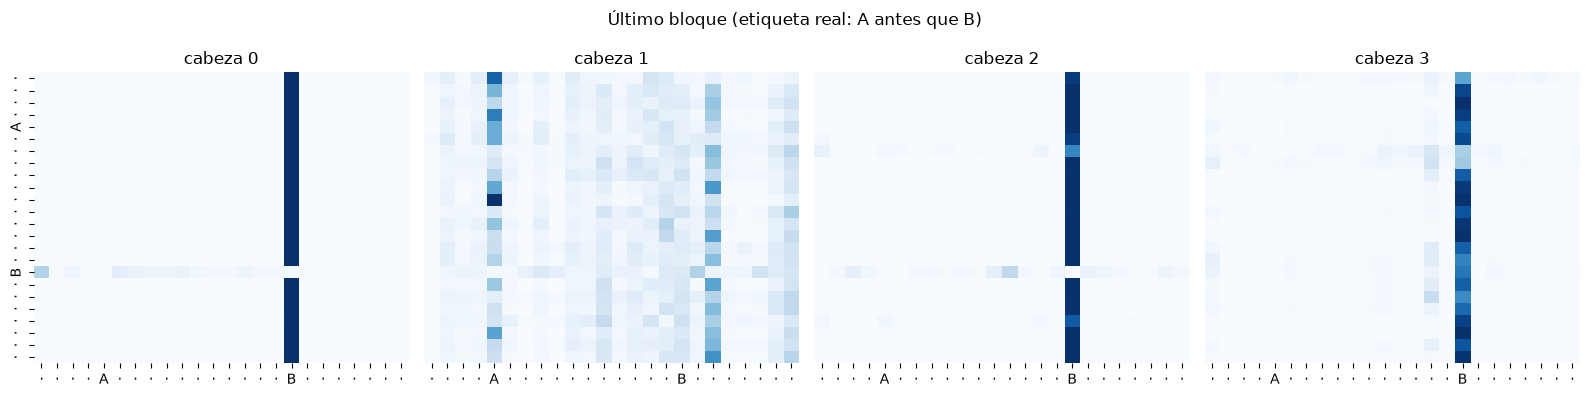

In [7]:
modelo = modelos_sint["(c) Transformer con posiciones"].eval()
ejemplo = X_sint_val[:1].to(dispositivo)
with torch.no_grad():
    x = modelo.tokens(ejemplo) + modelo.posiciones(torch.arange(24, device=dispositivo))
    x = modelo.bloques[0](x)
    _, pesos = modelo.bloques[1](x, devolver_pesos=True)
nombres = ["A" if t == 0 else "B" if t == 1 else "·" for t in ejemplo[0].tolist()]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for cabeza, ax in enumerate(axes):
    sns.heatmap(pesos[0, cabeza].cpu().numpy(), ax=ax, cmap="Blues", cbar=False,
                xticklabels=nombres, yticklabels=nombres if cabeza == 0 else False)
    ax.set_title(f"cabeza {cabeza}")
plt.suptitle(f"Último bloque (etiqueta real: {'A antes que B' if y_sint_val[0] else 'B antes que A'})")
plt.tight_layout()
plt.show()

**Interpretación:**

- El promedio de embeddings y el Transformer **sin posiciones** se quedan en el azar (0,49 y 0,50). Como vimos en el cuaderno 16, la self-attention sin codificación posicional es equivariante a permutaciones, y el promedio final la vuelve **invariante**: *A antes que B* y *B antes que A* producen exactamente la misma salida, así que ningún entrenamiento puede resolver la tarea.
- Con embeddings de posición, el Transformer la resuelve perfectamente (100 % en validación).
- El mapa de atención muestra cómo lo hace: en tres de las cuatro cabezas, casi todas las posiciones atienden a **B** (y en la cabeza 0, B atiende a A); la cabeza 1 reparte la atención entre A y B. Así, cada posición recibe la información de los dos tokens relevantes, **incluida su posición**, y el promedio final puede compararlas. Aquí la atención funciona como un mecanismo de **búsqueda**, justo lo que no ocurría en la tarea de sentimiento del cuaderno 16, donde un promedio bastaba.

---

<a id="ejercicio-3"></a>
<h2 style="color: #007ACC;">Ejercicio 3. Fine-tuning de BERT</h2>

**Objetivo:** ajustar modelos preentrenados en español para clasificar el sentimiento de tuits, comparando un modelo de dominio general con uno preentrenado en tuits y midiendo la variabilidad entre semillas.

Usaremos la parte en español del corpus [TweetSentiment Multilingual](https://huggingface.co/datasets/cardiffnlp/tweet_sentiment_multilingual) (Barbieri et al., 2022): 1 839 tuits de entrenamiento, 324 de validación y 870 de prueba, etiquetados como negativo (0), neutro (1) o positivo (2).

```python
base = "hf://datasets/cardiffnlp/tweet_sentiment_multilingual/data/spanish/"
tuits = load_dataset("json", data_files={s: base + f"{s}.jsonl" for s in ["train", "validation", "test"]})
```

1. Explora los datos (distribución de clases, longitud, ejemplos) y entrena una línea base TF-IDF + regresión logística. Usa el **F1 macro** como métrica principal.
2. Haz fine-tuning de dos modelos *uncased* (pasa los textos a minúsculas):
   - `dccuchile/bert-base-spanish-wwm-uncased` (BETO, preentrenado con Wikipedia, noticias, libros...),
   - `pysentimiento/robertuito-base-uncased` (RoBERTuito, preentrenado con 500 millones de tuits en español).

   Usa `Trainer` con 4 épocas, tasa de aprendizaje $5 \times 10^{-5}$, lotes de 16 y `max_length=128`. Repite cada fine-tuning con **3 semillas** distintas y reporta la media y la desviación estándar del F1 macro en **validación**.
3. ¿Cuánto varía el resultado entre semillas? ¿Es mayor o menor que la diferencia entre los dos modelos? ¿Qué implica para comparar modelos con un solo entrenamiento?
4. Elige el mejor modelo según validación y evalúa sus 3 semillas en **prueba**. Muestra la matriz de confusión de una de ellas: ¿qué clase es la más difícil?

In [8]:
base = "hf://datasets/cardiffnlp/tweet_sentiment_multilingual/data/spanish/"
tuits = load_dataset("json", data_files={s: base + f"{s}.jsonl" for s in ["train", "validation", "test"]})
tuits = tuits.map(lambda r: {"label": int(r["label"]), "text": r["text"].lower()})
NOMBRES = ["negativo", "neutro", "positivo"]
print(tuits)
for s in ["train", "validation", "test"]:
    print(s, dict(Counter(NOMBRES[e] for e in tuits[s]["label"])))
print("Palabras por tuit (mediana):", np.median([len(t.split()) for t in tuits["train"]["text"]]))
for r in tuits["train"].select(range(4)):
    print(f"[{NOMBRES[r['label']]}] {r['text']}")

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 1839
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 324
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 870
    })
})
train {'negativo': 613, 'neutro': 613, 'positivo': 613}
validation {'negativo': 108, 'neutro': 108, 'positivo': 108}
test {'negativo': 290, 'neutro': 290, 'positivo': 290}
Palabras por tuit (mediana): 16.0
[negativo] estoy hasta el ojete de que me digáis que tengo cara de mala leche
[neutro] @user por?  tenía pensado verla después de la segunda de daredevil
[positivo] esto de estar feliz mola
[negativo] ya no es tan divertido


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
lr = LogisticRegression(max_iter=2000, C=4).fit(tfidf.fit_transform(list(tuits["train"]["text"])),
                                               list(tuits["train"]["label"]))
pred_lr = lr.predict(tfidf.transform(list(tuits["validation"]["text"])))
f1_lr = f1_score(list(tuits["validation"]["label"]), pred_lr, average="macro")
print(f"TF-IDF + regresión logística: F1 macro en validación = {f1_lr:.3f}")

TF-IDF + regresión logística: F1 macro en validación = 0.571


In [10]:
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, Trainer, TrainingArguments


def ajustar(nombre_modelo, semilla):
    tok = AutoTokenizer.from_pretrained(nombre_modelo)
    ds = tuits.map(lambda lote: tok(lote["text"], truncation=True, max_length=128), batched=True)
    set_seed(semilla)
    modelo = AutoModelForSequenceClassification.from_pretrained(nombre_modelo, num_labels=3)
    argumentos = TrainingArguments(output_dir="checkpoints/tuits", learning_rate=5e-5, num_train_epochs=4,
                                   per_device_train_batch_size=16, per_device_eval_batch_size=64,
                                   weight_decay=0.01, warmup_steps=0.1, save_strategy="no",
                                   fp16=torch.cuda.is_available(), report_to="none", seed=semilla,
                                   disable_tqdm=True, logging_strategy="no")
    entrenador = Trainer(model=modelo, args=argumentos, train_dataset=ds["train"],
                         data_collator=DataCollatorWithPadding(tok))
    entrenador.remove_callback(transformers.PrinterCallback)  # sin registros en pantalla
    entrenador.train()
    # predicciones en validación y en prueba; las de prueba solo se miran para el modelo elegido
    pred_val = entrenador.predict(ds["validation"]).predictions.argmax(-1)
    pred_test = entrenador.predict(ds["test"]).predictions.argmax(-1)
    del entrenador, modelo  # libera la memoria de la GPU antes del siguiente entrenamiento
    torch.cuda.empty_cache()
    return pred_val, pred_test



transformers.logging.set_verbosity_error()  # oculta el informe de carga en cada repetición
MODELOS = {"BETO uncased": "dccuchile/bert-base-spanish-wwm-uncased",
           "RoBERTuito uncased": "pysentimiento/robertuito-base-uncased"}
SEMILLAS = [0, 1, 2]
y_val_t, y_test_t = list(tuits["validation"]["label"]), list(tuits["test"]["label"])
filas, predicciones_prueba = [], {}
inicio = time.perf_counter()
for nombre, ruta in MODELOS.items():
    for semilla in SEMILLAS:
        pred_val, pred_test = ajustar(ruta, semilla)
        filas.append({"modelo": nombre, "semilla": semilla,
                      "F1 macro validación": f1_score(y_val_t, pred_val, average="macro")})
        predicciones_prueba[(nombre, semilla)] = pred_test
print(f"Tiempo total: {time.perf_counter() - inicio:.0f} s")
val = pd.DataFrame(filas)
resumen = val.groupby("modelo")["F1 macro validación"].agg(["mean", "std", "min", "max"])
resumen.loc["TF-IDF + RL"] = [f1_lr, np.nan, np.nan, np.nan]
resumen.round(3)

Tiempo total: 189 s


,mean,std,min,max
modelo,,,,
BETO uncased,0.657,0.008,0.649,0.665
RoBERTuito uncased,0.724,0.006,0.719,0.731
TF-IDF + RL,0.571,NaN,NaN,NaN


Modelo elegido en validación: RoBERTuito uncased
F1 macro en PRUEBA: 0.722 ± 0.008 (3 semillas)
TF-IDF + RL en prueba: 0.502


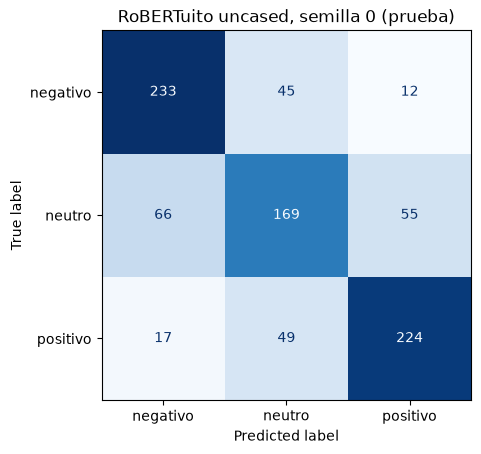

In [11]:
from sklearn.metrics import ConfusionMatrixDisplay

MEJOR = resumen.drop("TF-IDF + RL")["mean"].idxmax()
f1_test = [f1_score(y_test_t, predicciones_prueba[(MEJOR, s)], average="macro") for s in SEMILLAS]
pred_ejemplo, reales = predicciones_prueba[(MEJOR, SEMILLAS[0])], y_test_t
print(f"Modelo elegido en validación: {MEJOR}")
print(f"F1 macro en PRUEBA: {np.mean(f1_test):.3f} ± {np.std(f1_test, ddof=1):.3f} (3 semillas)")
print(f"TF-IDF + RL en prueba: {f1_score(list(tuits['test']['label']), lr.predict(tfidf.transform(list(tuits['test']['text']))), average='macro'):.3f}")
ConfusionMatrixDisplay.from_predictions(reales, pred_ejemplo, display_labels=NOMBRES, cmap="Blues", colorbar=False)
plt.title(f"{MEJOR}, semilla {SEMILLAS[0]} (prueba)")
plt.show()

**Interpretación:**

- Las clases están balanceadas (613 tuits por clase en entrenamiento) y los tuits son cortos (mediana de 16 palabras), con lenguaje coloquial, menciones (`@user`) y expresiones como *"mola"* o *"mala leche"*. Con 1 839 ejemplos, una bolsa de palabras no alcanza a cubrir esa variedad: TF-IDF obtiene un F1 macro de 0,57 en validación.
- RoBERTuito supera a BETO por 7 puntos (0,724 frente a 0,657). Los dos modelos tienen un tamaño similar; la diferencia está en el **dominio del preentrenamiento**: RoBERTuito vio 500 millones de tuits, con su ortografía, su jerga y sus emojis, y BETO sobre todo Wikipedia, noticias y otros textos formales (Gururangan et al., 2020).
- Con el mismo modelo y los mismos datos, el F1 varía hasta 1,6 puntos entre semillas (desviación estándar ≈ 0,007). Aquí la diferencia entre modelos es unas 10 veces mayor, pero cuando dos modelos difieren en uno o dos puntos, **un solo entrenamiento no basta** para saber cuál es mejor: hay que repetir con varias semillas y reportar la variabilidad (Dodge et al., 2020).
- En prueba, RoBERTuito obtiene 0,722 ± 0,008, frente a 0,502 de TF-IDF. La clase más difícil es **neutro**: solo 169 de 290 tuits neutros se clasifican bien, y los errores se reparten entre negativo y positivo. Los tuits neutros son heterogéneos (preguntas, noticias, opiniones tibias) y su frontera con las otras clases es subjetiva; en cambio, las confusiones directas entre positivo y negativo son pocas (12 y 17).

---

<a id="ejercicio-4"></a>
<h2 style="color: #007ACC;">Ejercicio 4. Sumarización y QA</h2>

**Objetivo:** evaluar un modelo de resumen fuera de su dominio de entrenamiento y calibrar un modelo de respuesta a preguntas para que se abstenga cuando no hay respuesta.

**Parte A: resumen fuera de dominio.** El modelo `csebuetnlp/mT5_multilingual_XLSum` del cuaderno 18 se ajustó con noticias de la BBC. Evalúalo con 50 noticias de **El País** del conjunto de prueba de [MLSUM](https://huggingface.co/datasets/reciTAL/mlsum) (Scialom et al., 2020):

```python
mlsum = load_dataset("parquet", data_files={"test": "hf://datasets/reciTAL/mlsum@refs/convert/parquet/es/test/0000.parquet"})["test"]
```

1. Calcula ROUGE-1, ROUGE-2 y ROUGE-L (con un tokenizador que respete las tildes, como en el cuaderno 18) del modelo y de las líneas base *lead-1* y *lead-3* (primera oración y primeras tres oraciones).
2. Compara con los resultados del cuaderno 18 en XL-Sum. ¿El modelo sigue superando a las líneas base? Compara la longitud media de los resúmenes generados y de referencia, y lee tres ejemplos: ¿en qué se diferencian los resúmenes de referencia de MLSUM y de XL-Sum?

**Parte B: saber cuándo no responder.** Usa el modelo de QA del cuaderno 18 (`mrm8488/distill-bert-base-spanish-wwm-cased-finetuned-spa-squad2-es`) y su función `responder`, que devuelve la respuesta, el puntaje del mejor fragmento y el puntaje "sin respuesta".

3. Toma 400 preguntas de prueba de SQAC. Para la mitad, usa su contexto original (**con respuesta**); para la otra mitad, empareja cada pregunta con el contexto de **otra** pregunta elegida al azar (**sin respuesta**, en la práctica).
4. Define la diferencia $\Delta = $ puntaje del fragmento $-$ puntaje sin respuesta. Grafica la distribución de $\Delta$ en los dos grupos.
5. Con la mitad de los ejemplos (calibración), elige el umbral de $\Delta$ que maximiza la exactitud de la decisión "responder / abstenerse". Con la otra mitad, reporta esa exactitud y el F1 de las respuestas, contando como correcta una abstención en una pregunta sin respuesta y como incorrecta una respuesta en una pregunta sin respuesta. Compara con no abstenerse nunca.

In [12]:
from transformers import AutoModelForSeq2SeqLM
from rouge_score import rouge_scorer

mlsum = load_dataset("parquet", data_files={
    "test": "hf://datasets/reciTAL/mlsum@refs/convert/parquet/es/test/0000.parquet"})["test"]
mlsum = mlsum.shuffle(seed=SEED).select(range(50))

tok_sum = AutoTokenizer.from_pretrained("csebuetnlp/mT5_multilingual_XLSum")
resumidor = AutoModelForSeq2SeqLM.from_pretrained("csebuetnlp/mT5_multilingual_XLSum").to(dispositivo).eval()


def resumir(textos, lote=8):
    resultado = []
    for i in range(0, len(textos), lote):
        entrada = tok_sum([re.sub(r"\s+", " ", t) for t in textos[i:i + lote]], return_tensors="pt",
                          padding=True, truncation=True, max_length=512).to(dispositivo)
        with torch.no_grad():
            salida = resumidor.generate(**entrada, max_new_tokens=84, num_beams=4, no_repeat_ngram_size=2)
        resultado += tok_sum.batch_decode(salida, skip_special_tokens=True)
    return resultado


class TokenizadorEspanol:
    def tokenize(self, texto):
        return re.findall(r"\w+", texto.lower())


evaluador = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], tokenizer=TokenizadorEspanol())


def rouge(predicciones, referencias):
    puntajes = [evaluador.score(r, p) for p, r in zip(predicciones, referencias)]
    return {m: np.mean([s[m].fmeasure for s in puntajes]) for m in ["rouge1", "rouge2", "rougeL"]}


def lead(texto, n):
    return " ".join(re.split(r"(?<=[.!?])\s+", texto.strip())[:n])


textos, referencias = list(mlsum["text"]), list(mlsum["summary"])
generados = resumir(textos)
tabla = pd.DataFrame({"lead-1": rouge([lead(t, 1) for t in textos], referencias),
                      "lead-3": rouge([lead(t, 3) for t in textos], referencias),
                      "mT5 XL-Sum": rouge(generados, referencias)}).T
tabla["palabras por resumen"] = [np.mean([len(lead(t, 1).split()) for t in textos]),
                                 np.mean([len(lead(t, 3).split()) for t in textos]),
                                 np.mean([len(g.split()) for g in generados])]
print(f"Palabras por resumen de referencia: {np.mean([len(r.split()) for r in referencias]):.1f}")
tabla.round(3)

Palabras por resumen de referencia: 22.5


,rouge1,rouge2,rougeL,palabras por resumen
lead-1,0.223,0.064,0.174,25.68
lead-3,0.209,0.070,0.154,80.14
mT5 XL-Sum,0.224,0.057,0.181,19.46


In [13]:
for i in range(3):
    print(f"[{i}] Título: {mlsum[i]['title']}")
    print(f"    Referencia: {referencias[i]}")
    print(f"    mT5:        {generados[i]}\n")

[0] Título: Enredarse innecesariamente
    Referencia: En un sistema como el español, de investidura parlamentaria del presidente del Ejecutivo, es irrenunciable que los diputados tengan libertad sin restricciones para determinar el sentido de su voto
    mT5:        En los últimos años, el debate sobre la reforma de la Constitución y la disolución automática de las Cámaras de Diputados ha vuelto a poner en riesgo la formación del Gobierno.
[1] Título: Fuga desesperada de una franja de Gaza apenas habitable
    Referencia: Decenas de miles de palestinos abandonan el enclave a través de Egipto tras más de una década de guerras y bloqueo
    mT5:        Un grupo de palestinos se prepara para cruzar a Egipto.
[2] Título: Los cuatro últimos ‘fichajes’ de Elcano
    Referencia: Un historiador militar descubre la procedencia canaria de los cuatro tripulantes que se sumaron a última hora a la expedición de Magallanes
    mT5:        El navío de Magallanes-Elcano se encuentra en la isla de Ten

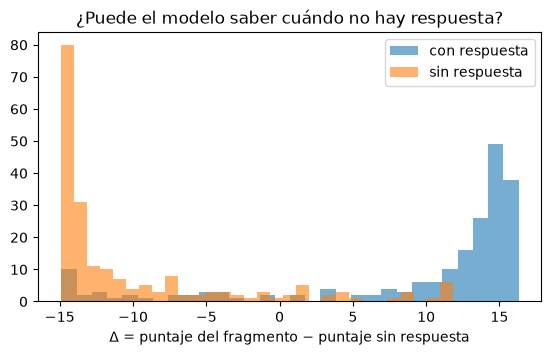

In [14]:
import json
import random
import string
from huggingface_hub import hf_hub_download
from transformers import AutoModelForQuestionAnswering

nombre_qa = "mrm8488/distill-bert-base-spanish-wwm-cased-finetuned-spa-squad2-es"
tok_qa = AutoTokenizer.from_pretrained(nombre_qa)
modelo_qa = AutoModelForQuestionAnswering.from_pretrained(nombre_qa).to(dispositivo).eval()


def responder(pregunta, contexto, max_largo=30):
    entrada = tok_qa(pregunta, contexto, truncation="only_second", max_length=384,
                     return_offsets_mapping=True, return_tensors="pt")
    offsets = entrada.pop("offset_mapping")[0].tolist()
    es_contexto = np.array(entrada.sequence_ids(0)) == 1
    with torch.no_grad():
        salida = modelo_qa(**entrada.to(dispositivo))
    ini, fin = salida.start_logits[0].cpu().numpy(), salida.end_logits[0].cpu().numpy()
    mejor, puntaje = (0, 0), -np.inf
    for i in [i for i in np.argsort(ini)[::-1][:20] if es_contexto[i]]:
        for j in [j for j in np.argsort(fin)[::-1][:20] if es_contexto[j]]:
            if i <= j < i + max_largo and ini[i] + fin[j] > puntaje:
                mejor, puntaje = (i, j), ini[i] + fin[j]
    return contexto[offsets[mejor[0]][0]:offsets[mejor[1]][1]], float(puntaje), float(ini[0] + fin[0])


def normalizar(texto):
    texto = "".join(c for c in texto.lower() if c not in set(string.punctuation + "¿¡«»"))
    return " ".join(re.sub(r"\b(el|la|los|las|un|una|unos|unas)\b", " ", texto).split())


def f1(prediccion, referencia):
    p, r = normalizar(prediccion).split(), normalizar(referencia).split()
    comunes = sum((Counter(p) & Counter(r)).values())
    return 0.0 if comunes == 0 else 2 * comunes / (len(p) + len(r))


with open(hf_hub_download("PlanTL-GOB-ES/SQAC", "test.json", repo_type="dataset"), encoding="utf-8") as f:
    sqac = json.load(f)["data"]
preguntas = [(qa["question"], p["context"], [a["text"] for a in qa["answers"]])
             for art in sqac for p in art["paragraphs"] for qa in p["qas"]]
rnd = random.Random(SEED)
rnd.shuffle(preguntas)
preguntas = preguntas[:400]

filas = []
for i, (pregunta, contexto, respuestas) in enumerate(preguntas):
    con_respuesta = i % 2 == 0
    if not con_respuesta:  # contexto de otra pregunta distinta
        contexto = rnd.choice([c for _, c, _ in preguntas if c != contexto])
    r, puntaje, nulo = responder(pregunta, contexto)
    filas.append({"con_respuesta": con_respuesta, "delta": puntaje - nulo, "respuesta": r,
                  "f1": max(f1(r, a) for a in respuestas) if con_respuesta else 0.0})
qa = pd.DataFrame(filas)

plt.figure(figsize=(6.5, 3.5))
for valor, nombre in [(True, "con respuesta"), (False, "sin respuesta")]:
    plt.hist(qa.loc[qa.con_respuesta == valor, "delta"], bins=30, alpha=0.6, label=nombre)
plt.xlabel("Δ = puntaje del fragmento − puntaje sin respuesta")
plt.legend()
plt.title("¿Puede el modelo saber cuándo no hay respuesta?")
plt.show()

In [15]:
calibracion, evaluacion = qa.iloc[:200], qa.iloc[200:]


def exactitud_decision(df, umbral):
    responde = df.delta > umbral
    return (responde == df.con_respuesta).mean()


def puntaje_final(df, umbral):
    """F1 por pregunta: abstenerse vale 1 si no hay respuesta y 0 si la hay."""
    responde = df.delta > umbral
    return np.where(responde, df.f1, (~df.con_respuesta).astype(float)).mean()


umbrales = np.linspace(qa.delta.min(), qa.delta.max(), 200)
umbral = umbrales[np.argmax([exactitud_decision(calibracion, u) for u in umbrales])]
pd.DataFrame({
    "exactitud de la decisión": [exactitud_decision(evaluacion, -np.inf), exactitud_decision(evaluacion, umbral)],
    "F1 con abstención": [puntaje_final(evaluacion, -np.inf), puntaje_final(evaluacion, umbral)],
}, index=["nunca abstenerse", f"umbral Δ > {umbral:.2f}"]).round(3)

,exactitud de la decisión,F1 con abstención
nunca abstenerse,0.50,0.368
umbral Δ > 1.86,0.88,0.779


**Interpretación:**

*Parte A.*

- En las noticias de El País, el modelo **ya no supera** a las líneas base: su ROUGE-1 (0,224) es igual al de *lead-1* (0,223), y su ROUGE-2 es menor que el de *lead-1* y *lead-3*. En XL-Sum (cuaderno 18) superaba a la primera oración por 11 puntos de ROUGE-1.
- Las referencias de MLSUM son los **subtítulos** de las noticias de El País (*"Decenas de miles de palestinos abandonan el enclave a través de Egipto tras más de una década de guerras y bloqueo"*), y las de XL-Sum son las frases introductorias de la BBC. El modelo aprendió el estilo de la BBC, y en El País produce resúmenes más genéricos y cortos (19 palabras frente a 22,5 de las referencias), como *"Un grupo de palestinos se prepara para cruzar a Egipto"*.
- Un modelo ajustado para una tarea aprende también el **estilo y el dominio** de sus datos. Antes de usarlo con otros textos hay que evaluarlo con esos textos.

*Parte B.*

- La diferencia Δ separa bien los dos grupos: las preguntas con respuesta se concentran en Δ ≈ 10–16 y las que no la tienen, en Δ ≈ −15. Ajustado con SQuAD 2.0, el modelo sí aprendió a reconocer cuándo el contexto no contiene la respuesta.
- Con el umbral elegido en calibración (Δ > 1,86), la decisión de responder o abstenerse es correcta en el 88 % de los casos de evaluación, y el F1 con abstención sube de 0,37 a 0,78. Sin abstención, el modelo "responde" algo a todas las preguntas sin respuesta.
- Algunas preguntas que sí tienen respuesta reciben un Δ muy negativo: el modelo se abstiene cuando no debería (una causa posible es que la respuesta quede fuera de los 384 tokens a los que se trunca el contexto). El umbral es una **decisión de diseño**: en un sistema médico o legal conviene abstenerse más a menudo, aunque se pierdan algunas respuestas correctas.

<a id="referencias"></a>
<h2 style="color: #007ACC;">Referencias</h2>

- Tunstall, L., von Werra, L. & Wolf, T. (2022). *Natural Language Processing with Transformers*. O'Reilly Media.
- Jurafsky, D. & Martin, J. H. *Speech and Language Processing* (3.ª ed. borrador). [web.stanford.edu/~jurafsky/slp3](https://web.stanford.edu/~jurafsky/slp3/)
- Vaswani, A. et al. (2017). Attention Is All You Need. *NeurIPS*.
- Dao, T. et al. (2022). FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness. *NeurIPS*.
- Barbieri, F., Espinosa Anke, L. & Camacho-Collados, J. (2022). XLM-T: Multilingual Language Models in Twitter for Sentiment Analysis and Beyond. *LREC*.
- Pérez, J. M. et al. (2022). RoBERTuito: a pre-trained language model for social media text in Spanish. *LREC*.
- Gururangan, S. et al. (2020). Don't Stop Pretraining: Adapt Language Models to Domains and Tasks. *ACL*.
- Dodge, J. et al. (2020). Fine-Tuning Pretrained Language Models: Weight Initializations, Data Orders, and Early Stopping. *arXiv:2002.06305*.
- Scialom, T. et al. (2020). MLSUM: The Multilingual Summarization Corpus. *EMNLP*.
- Rajpurkar, P., Jia, R. & Liang, P. (2018). Know What You Don't Know: Unanswerable Questions for SQuAD. *ACL*.